In [2]:
# 糖尿病数据集介绍 https://www.kaggle.com/datasets/alihaider006/diabetes-disease-prediction-dataset
# 共计 768 条数据，8 个特征变量和 1 个目标变量（是否糖尿病）。
# Pregnancies:怀孕次数，Glucose:血糖
# BloodPressure:血压值，SkinThickness:皮肤厚度
# Insulin胰岛素，BMI:身体质量指数
# DiabetesPedigreeFunction糖尿病遗传函数，Age：年龄
# Outcome：糖尿病标签，1表示有糖尿病，0表示没有糖尿病
# 该数据集源自皮马印第安人糖尿病数据库。

In [3]:
import pandas as pd
import numpy as np

df = pd.read_csv('diabetes.csv')
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [4]:
# 分离特征和标签
X = df.drop('Outcome', axis=1)
y = df['Outcome']
print("特征数据形状:", X.shape)
print("标签数据形状:", y.shape)

特征数据形状: (768, 8)
标签数据形状: (768,)


In [5]:
# 分离训练集和测试集
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("训练集形状:", X_train.shape, y_train.shape)
print("测试集形状:", X_test.shape, y_test.shape)

训练集形状: (614, 8) (614,)
测试集形状: (154, 8) (154,)


In [6]:
# 使用标准化处理特征数据
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("标准化后训练集形状:", X_train_scaled.shape)
print("标准化后测试集形状:", X_test_scaled.shape)

标准化后训练集形状: (614, 8)
标准化后测试集形状: (154, 8)


In [7]:
# 使用逻辑回归模型进行训练
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
# 在测试集上评估模型
accuracy = model.score(X_test_scaled, y_test)
print("测试集准确率:", accuracy)

测试集准确率: 0.7532467532467533


In [8]:
# 数据分析与预处理
# Glucose:血糖，BloodPressure:血压值，SkinThickness:皮肤厚度，Insulin胰岛素，BMI:身体质量指数应该是没有0值的


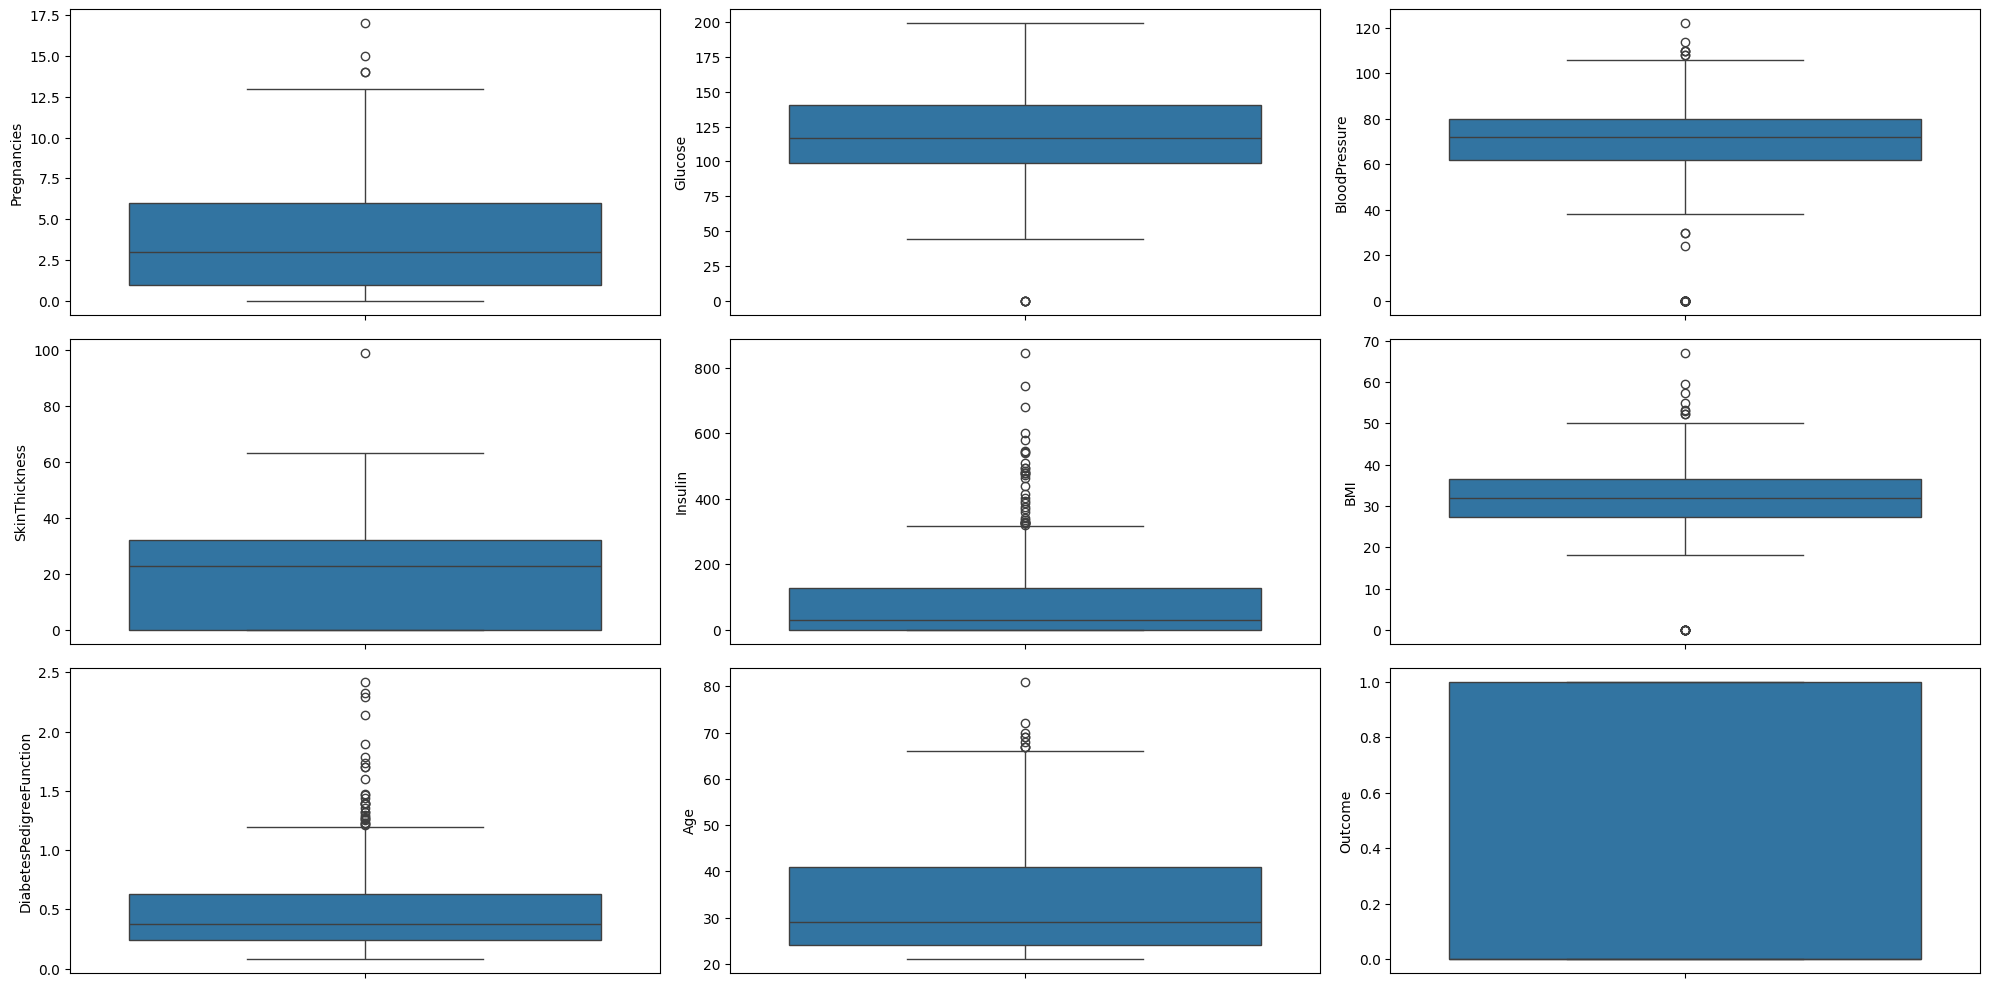

In [9]:
# 绘制数据集
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

fig, axes = plt.subplots(3, 3, figsize=(20, 10))
axes = axes.flatten()

index = 0
for k, v in df.items():
    sns.boxplot(y=k, data=df, ax=axes[index])
    index += 1

plt.tight_layout()
plt.show()

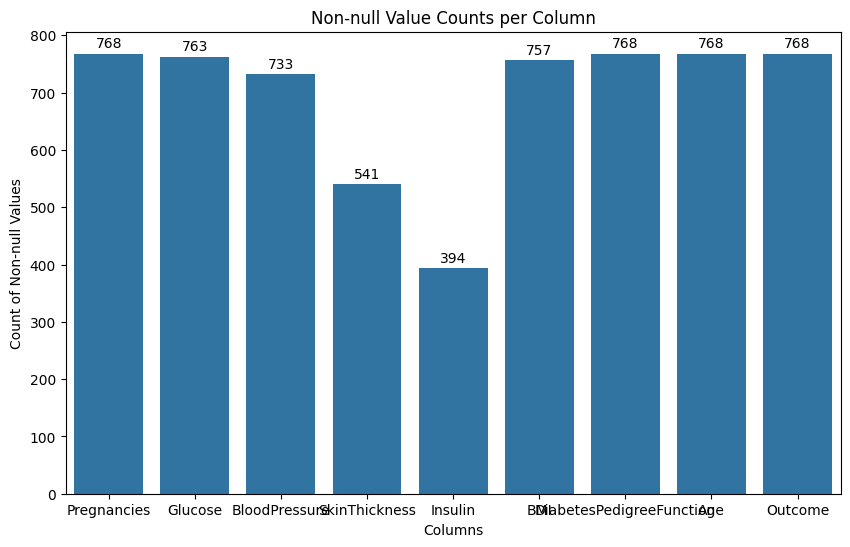

In [10]:
# 可以看到Glucose:血糖，BloodPressure:血压值，SkinThickness:皮肤厚度，Insulin胰岛素，BMI均有0值

# 将这些0值替换为NaN以便后续处理
zero_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[zero_columns] = df[zero_columns].replace(0, np.nan)  # 将0值替换为NaN
# 用bar图展示每列的非空值,并显示数值标签
non_null_counts = df.notnull().sum()
plt.figure(figsize=(10, 6))
sns.barplot(x=non_null_counts.index, y=non_null_counts.values)
for i, v in enumerate(non_null_counts.values):
    plt.text(i, v + 5, str(v), ha='center', va='bottom')
plt.title('Non-null Value Counts per Column')
plt.ylabel('Count of Non-null Values')
plt.xlabel('Columns')
plt.show()


In [11]:
# 去除缺失值超过20%的列
threshold = len(df) * 0.8
df_clean = df.dropna(thresh=threshold, axis=1)
print("去除缺失值超过20%的列后数据集形状:", df_clean.shape)
print(df_clean.head())
# 用均值填充缺失值
df_clean = df_clean.fillna(df_clean.mean())
print("填充缺失值后数据集形状:", df_clean.shape)

去除缺失值超过20%的列后数据集形状: (768, 7)
   Pregnancies  Glucose  BloodPressure   BMI  DiabetesPedigreeFunction  Age  \
0            6    148.0           72.0  33.6                     0.627   50   
1            1     85.0           66.0  26.6                     0.351   31   
2            8    183.0           64.0  23.3                     0.672   32   
3            1     89.0           66.0  28.1                     0.167   21   
4            0    137.0           40.0  43.1                     2.288   33   

   Outcome  
0        1  
1        0  
2        1  
3        0  
4        1  
填充缺失值后数据集形状: (768, 7)


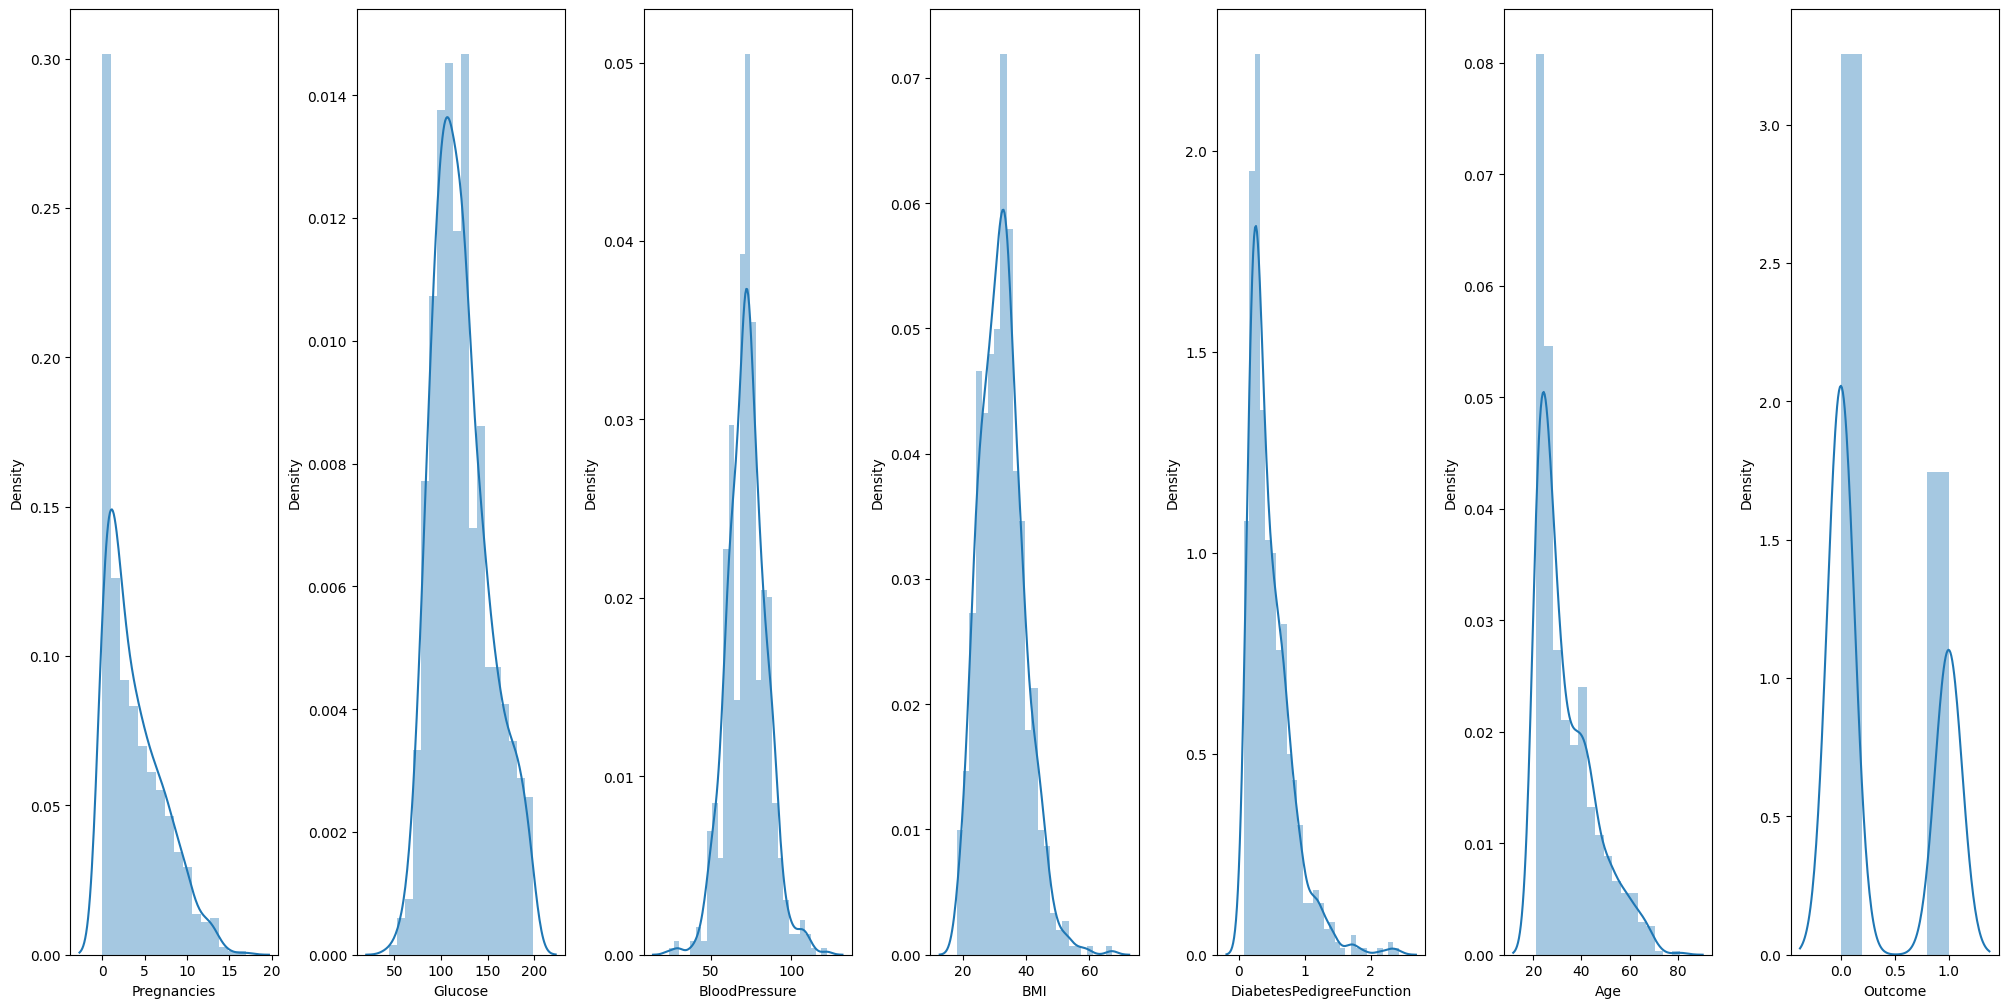

In [12]:
# 然后观察这些特征清理版
import warnings
warnings.filterwarnings("ignore")

fig, axs = plt.subplots(ncols=7,nrows=1, figsize=(20,10))
axs = axs.flatten()
index = 0
for k, v in df_clean.items():
    sns.distplot(v, ax=axs[index])
    index += 1
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
plt.show()

In [13]:
# 直方图显示，列pregnancies，Diabetespedigreefunction， age具有高度偏态分布。
# 其他列似乎具有数据的正态或双模分布。

<Axes: >

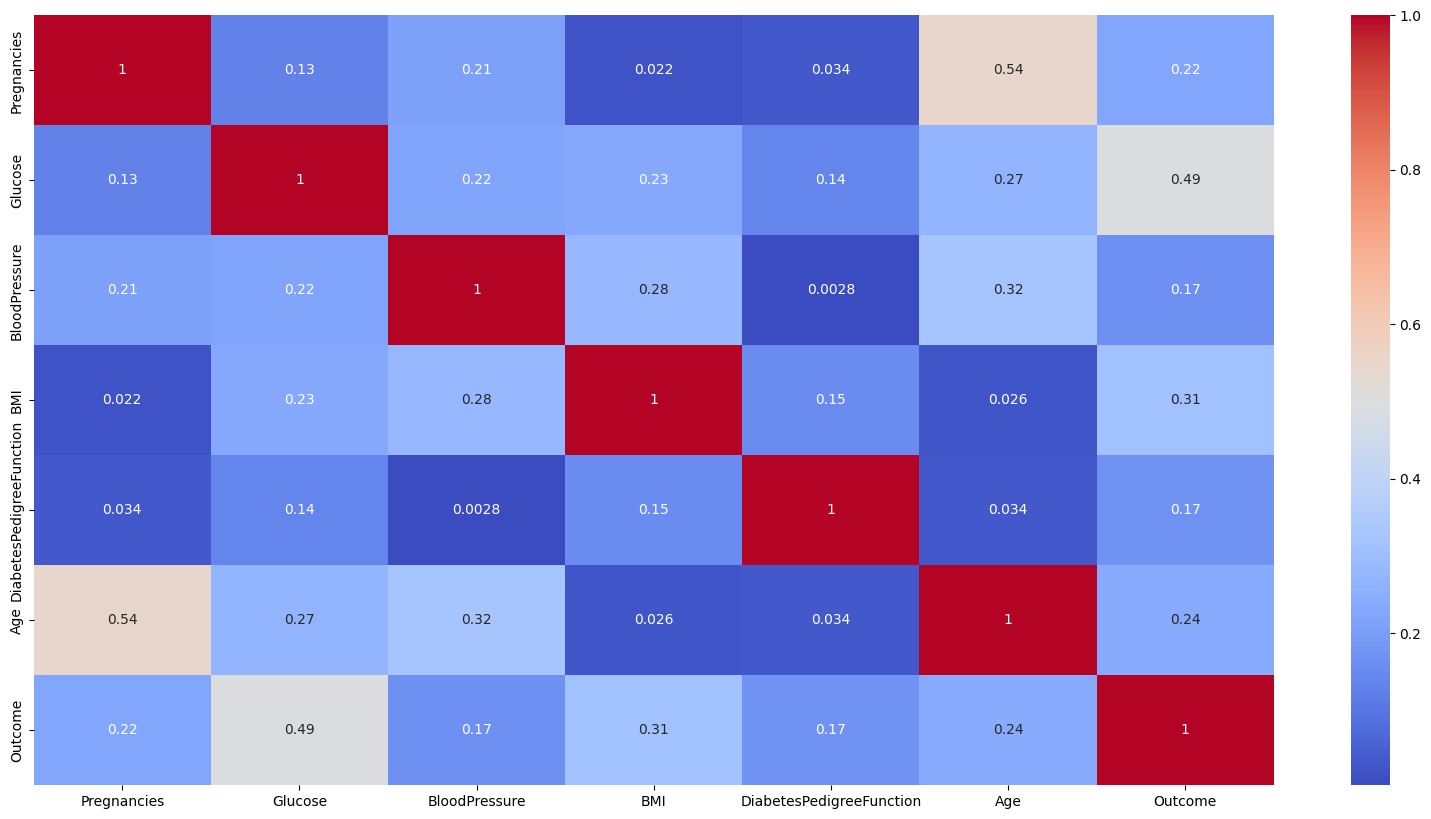

In [14]:
# 然后绘制数据的两两相关性
plt.figure(figsize=(20,10))
sns.heatmap(df_clean.corr().abs(), annot=True, cmap='coolwarm')

In [15]:
# 从相关矩阵可以看出，
# AGE和pregnancies是高度相关的特征。年龄越大，怀孕次数越多。
# Glucose和outcome相关性大。

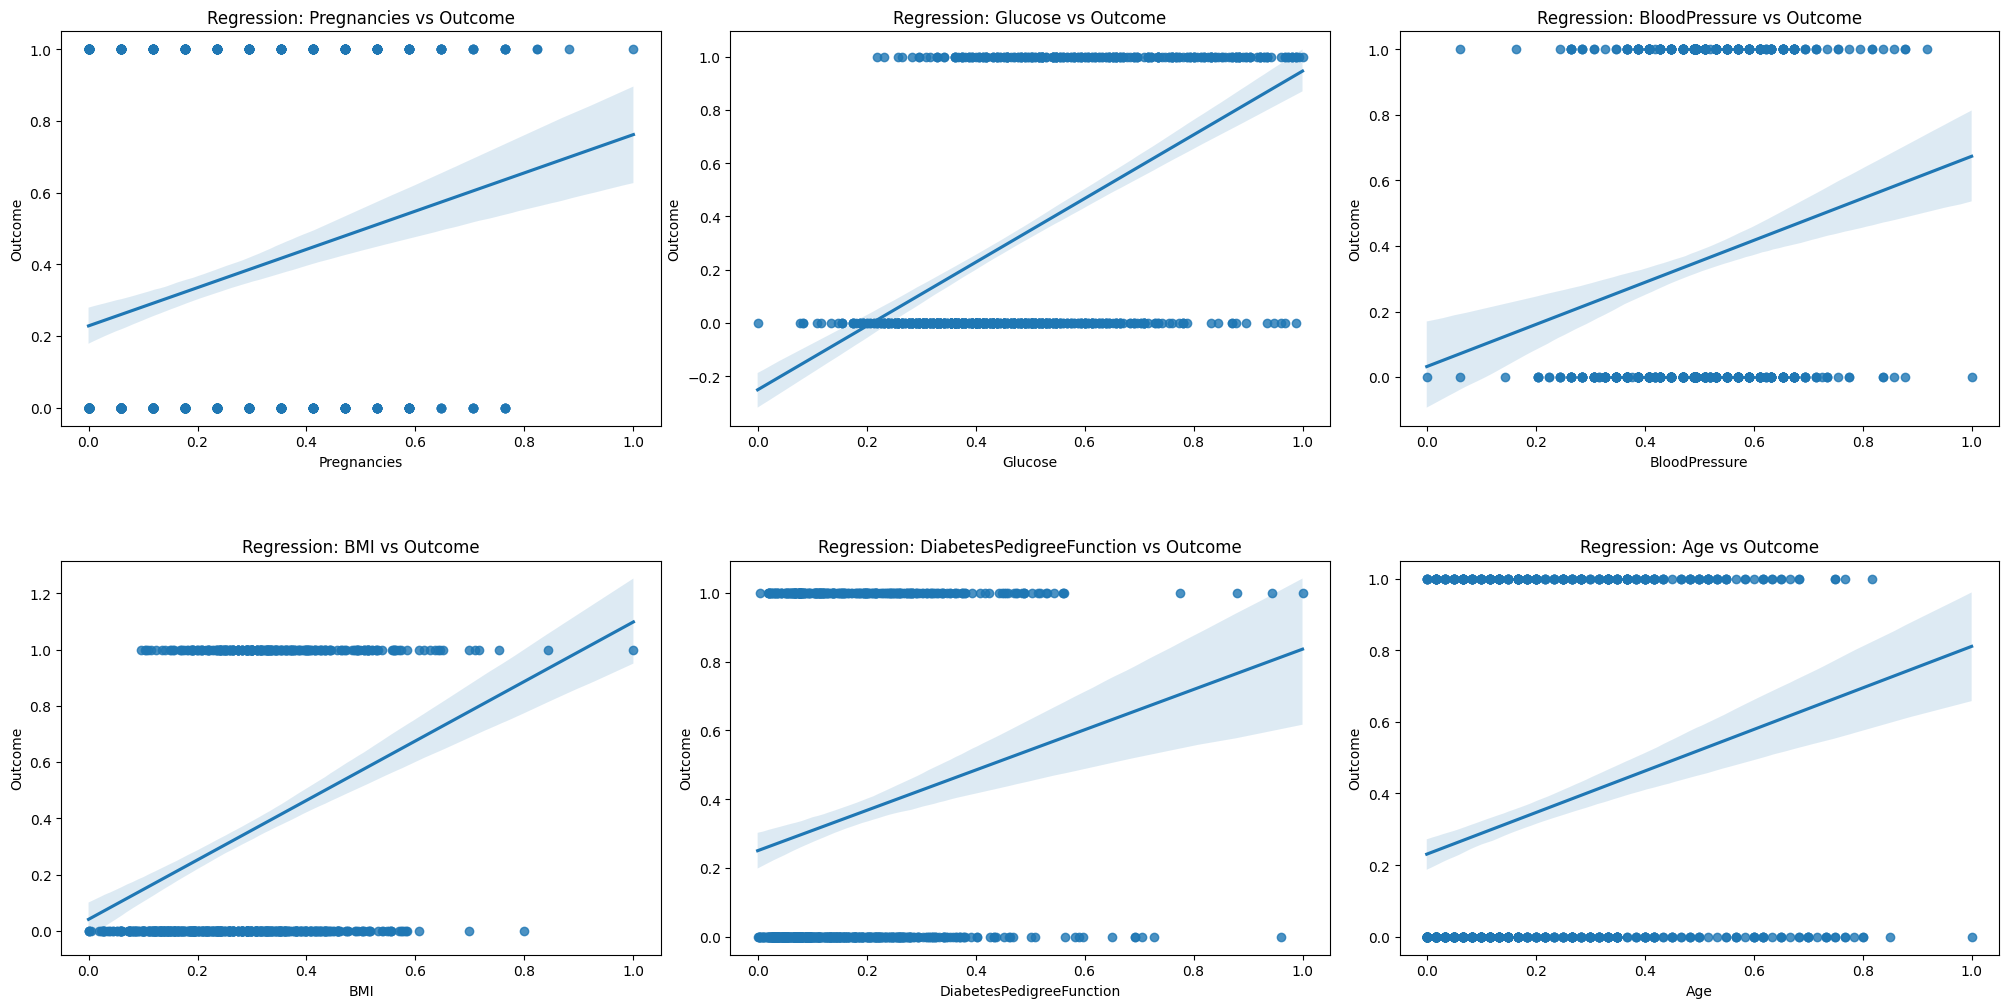

In [16]:
# 让我们绘制这些列
from sklearn import preprocessing

# 创建MinMaxScaler对象，用于将数据缩放到指定范围（默认[0, 1]）。这种标准化方法能消除量纲影响，使不同特征具有可比性
min_max_scaler = preprocessing.MinMaxScaler()
x = df_clean.drop('Outcome', axis=1)
# min_max_scaler.fit_transform(x)对特征数据x进行拟合和转换：计算每列的最小值和最大值，然后将数据线性缩放到[0, 1]区间。
# 将缩放后的NumPy数组转换回Pandas DataFrame，并保留原列名，便于后续处理
x = min_max_scaler.fit_transform(x) # 返回的是一个NumPy数组
x = pd.DataFrame(x, columns=df_clean.columns[:-1])  # 转换为DataFrame并设置列名
y = df_clean['Outcome']

fig, axs = plt.subplots(ncols=3, nrows=2, figsize=(20,10))
axs = axs.flatten()
for i, col_name in enumerate(x.columns):
    sns.regplot(y=y, x=x[col_name], ax=axs[i])
    axs[i].set_title(f'Regression: {col_name} vs Outcome')
plt.tight_layout(pad=0.4, w_pad=0.5, h_pad=5.0)
plt.show()

In [17]:
# 通过这些分析，可以尝试用Pregnancies:怀孕次数，Glucose:血糖
# BloodPressure:血压值，BMI:身体质量指数
# DiabetesPedigreeFunction糖尿病遗传函数，Age：年龄来预测Outcome
# 可尝试的，用Glucose:血糖，BloodPressure:血压值，BMI:身体质量指数

In [18]:
# 逻辑回归
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, KFold

model =LogisticRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, x, y, cv=kf, scoring='accuracy')
print("交叉验证准确率:", scores)
print("平均准确率:", scores.mean())


交叉验证准确率: [0.77922078 0.77922078 0.74675325 0.81045752 0.73856209]
平均准确率: 0.7708428826075885


In [19]:
# 用Glucose:血糖，BloodPressure:血压值，BMI:身体质量指数三个特征预测
x1 = df_clean[['Glucose', 'BloodPressure', 'BMI']]
y1 = df_clean['Outcome']
model1 =LogisticRegression()
scores1 = cross_val_score(model1, x1, y1, cv=kf, scoring='accuracy')
print("仅用三个特征交叉验证准确率:", scores1)
print("仅用三个特征平均准确率:", scores1.mean())

仅用三个特征交叉验证准确率: [0.76623377 0.77922078 0.74025974 0.81045752 0.7254902 ]
仅用三个特征平均准确率: 0.7643323996265172


In [20]:
# 感知机
from sklearn.linear_model import Perceptron
model2 = Perceptron()
scores2 = cross_val_score(model2, x, y, cv=kf, scoring='accuracy')
print("感知机交叉验证准确率:", scores2)
print("感知机平均准确率:", scores2.mean())  

感知机交叉验证准确率: [0.76623377 0.69480519 0.64935065 0.73202614 0.73856209]
感知机平均准确率: 0.7161955691367456
